In [1]:
import torch
from d2l import torch as d2l
import torch.nn.functional as F


In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import math

In [3]:
batch_size=25
num_steps=35
data=d2l.TimeMachine(batch_size, num_steps)
train_iter=data.get_dataloader(False)
vocab=data.vocab

In [4]:
def rnn(inputs,state,params):
    W_xh,W_hh,b_h,W_hq,b_q=params
    H,=state
    outputs=[]
    for X in inputs:
        H_new=torch.tanh(torch.mm(X,W_xh)+torch.mm(H,W_hh)+b_h)
        Y=torch.mm(H_new,W_hq)+b_q
        outputs.append(Y)
    return torch.cat(outputs,dim=0),(H_new,)



def init_weight(vocab_size,hidden_size,device):
    W_xh=torch.normal(0,1,(vocab_size,hidden_size),device=device)*0.01
    W_hh=torch.normal(0,1,(hidden_size,hidden_size),device=device)*0.01
    b_h=torch.zeros(hidden_size,device=device)
    W_hq=torch.normal(0,1,(hidden_size,vocab_size),device=device)*0.01
    b_q=torch.zeros(vocab_size,device=device)
    params=[W_xh,W_hh,b_h,W_hq,b_q]
    for param in params:
        param.requires_grad_(True)
    return params

In [5]:
class RNNModule:
    def __init__(self,vocab_size,hidden_size,device):
        self.hidden_size=hidden_size
        self.vocab_size=vocab_size
        self.params=init_weight(vocab_size,hidden_size,device)
        self.device=device

    def __call__(self,X,state):
        X = F.one_hot(X.T, self.vocab_size).type(torch.float32)
        return rnn(X,state,self.params)
    
    def init_hidden(self,batch_size):
        return (torch.zeros((batch_size,self.hidden_size),device=self.device),)

In [6]:
def predict_full(prefix,vocab,target_length,net,device):
    state=net.init_hidden(1)
    outputs=[vocab[prefix[0]]]
    #prewarm
    for x in prefix[1:]:
        _,state=net(torch.tensor(outputs[-1],device=device).reshape((1,1)),state)
        outputs.append(vocab[x])

    #pred
    for _ in range(target_length):
        y,state=net(torch.tensor(outputs[-1],device=device).reshape(1,1),state)
        outputs.append(int(torch.argmax(y,dim=1).reshape(1)))

    return ''.join([vocab.idx_to_token[idx] for idx in outputs])



In [7]:
def gradient_clip(net,theta):
    if isinstance(net,torch.nn.Module):
        params=[param for param in net.params if param.requires_grad]
    else: 
        params=net.params
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params)) 
    if norm > theta:  
        for param in params:  
            param.grad[:] *= theta / norm

In [8]:
def train_epoch(net,loss,updater,device,use_random_iter,train_iter,theta):
    states, timer = None, d2l.Timer() 
    metric = d2l.Accumulator(2) # 训练损失之和,词元数量
    for X,Y in train_iter:
        if states==None or use_random_iter:
            states=net.init_hidden(batch_size)
        else:
            if isinstance(states, tuple):
                states = tuple(s.detach() for s in states)   # ✅ tuple
            else:
                states = states.detach()   
        y=Y.T.reshape(-1)
        X=X.to(device)
        y=y.to(device)
        y_hat,states=net(X,states)
        l = loss(y_hat,y.long()).mean()

        l.backward()
        gradient_clip(net,theta)
        updater(batch_size=1)
        metric.add(l * y.numel(), y.numel()) 
    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()  
     



In [9]:
def train_ch8(net, train_iter, vocab, lr, num_epochs, device,  use_random_iter=False):
    """训练模型(定义见第8章)""" 
    loss = torch.nn.CrossEntropyLoss() 
    animator = d2l.Animator(xlabel='epoch', ylabel='perplexity',
                            legend=['train'], xlim=[10, num_epochs]) 
     # 初始化 
    if isinstance(net, torch.nn.Module):  
        updater = torch.optim.SGD(net.parameters(), lr) 
    else:  
        updater = lambda batch_size: d2l.sgd(net.params, lr, batch_size)  
    predict_f = lambda prefix: predict_full(prefix, vocab,50, net, device) 
    # 训练和预测 
    for epoch in range(num_epochs):  
        ppl, speed = train_epoch(net,loss,updater,device,use_random_iter, train_iter,1) 
        if (epoch + 1) % 10 == 0:  
            print(predict_full('time traveller' ,vocab,50, net, device)) 
            animator.add(epoch + 1, [ppl]) 
    print(f'困惑度 {ppl:.1f}, {speed:.1f} 词元/秒 {str(device)}') 
    print(predict_full('time traveller' ,vocab,50, net, device)) 
    print(predict_full('traveller' ,vocab,50, net, device))

困惑度 8.6, 39473.2 词元/秒 cuda:0
time travellere ine outhe oughe t the th on ore of f onghe t of 
travellere and on ond on ore th we onghe we we an thime on 


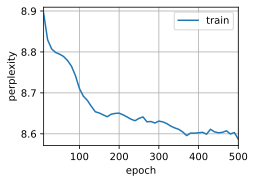

In [10]:
num_epochs, lr = 500, 1 
num_hiddens = 512 
net = RNNModule(len(vocab), num_hiddens, torch.device('cuda:0'))
train_ch8(net, train_iter, vocab, lr, num_epochs,torch.device('cuda:0'))